# 4.2 Laser Scanner

One of the most widely used types of range/bearing sensors is the 2D LiDAR (*Light Detection And Ranging*) or laser scanner. Their principle of operation is simple: the sensor emits a pulse of light of a particular frequency, and waits for it to be reflected back by the environment. Once the reflected pulse is received, the range $r$ to the obstacle can be calculated from the *time of flight* (ToF) $\Delta t$, that is, the round-trip time of the pulse: $r = \frac{c \, \Delta t}{2}$, being $c$ the speed of light.


A 2D scanner repeats this operation many times while rotating around its own center, thus obtaining information about the distance to the environment at different angles on its plane of operation. The main parameters that describe a laser scanner are:

- The angle increment between one measurement and the next is the **angular resolution** of the scanner, and determines how detailed the complete measurement is.
- The **field of view (FOV)** determines the angle limits of where the scan starts and stops. While some commercial LiDARs are capable of scanning all around themselves, it is often necessary to limit the FOV due to where the sensor is mounted on the robot (as we want to prevent the sensor from observing the body of the robot itself).
- The **max distance**, past which the sensor is not able to produce a measurement at all.
- The **noise**, of course. You know how this goes by now: sensor measurements are never fully reliable. Depending on the specifics of the sensor, the uncertainty of the measurements might only be reported for the *range* reading $r$ (that is, a scalar **variance** $\sigma_r^2$), or for both the range and the angle $\alpha$ (a **covariance matrix** $Q$).  

<figure style="text-align:center">
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/sick_and_hokuyo_laser_scanners.png" width="600px" alt="">
    <figcaption>Fig. 1. Top row, 2D laser scanners from <a href="https://www.sick.com/es/es/catalog/productos/safety/escaner-laser-de-seguridad/c/g569359" target="_blank">SICK</a>. Bottom row, left, 2D laser scanners from <a href="https://www.hokuyo-aut.jp/search/?cate01=1&cate02=1&cate03=" target="_blank">Hokuyo</a>, right, illustration of the field of view of some models of this brand.</figcaption>
</figure>

Let's create a simulated Laser Scanner with these parameters and test it out!

In [1]:
# In case of using Google Colab, mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    # Change directory to this chapter's folder in your Drive copy of the course repo:
    %cd '/content/drive/MyDrive/Colab Notebooks/uma_robotics_2027/Chapter 04. Robot sensing'
except ImportError:
    pass

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets

import sys
sys.path.append("..")
from utils.laser.laser2D import Laser2D
from utils.DrawRobot import DrawRobot
from utils.tcomp import tcomp

### Creating the scanner and the map

We will use the `Laser2D` class imported above. The constructor of this class expects the parameters we just discussed:
- `FOV` -- Sensor field of view (radians)
- `resolution` -- Sensor resolution (radians)
- `max_distance` -- Max operating distance of the sensor (meters)
- `noise_cov` -- covariance matrix $Q$ characterizing sensor noise
- `pose` -- sensor pose $\mathbf{x} = [x, y, \theta]^T$ (column vector)

The following function shows you how to create an instance of the `Laser2D` class:

In [2]:
def create_laser_at_origin(FOV, resolution, max_distance, noise_cov):
    origin_pose = np.vstack([0, 0, 0])
    laser = Laser2D(FOV, resolution, max_distance, noise_cov, origin_pose)
    return laser

The `Laser2D` class has two important methods: `set_pose()`, to tell it where to take an observation from; and `take_observation()`, which does exactly what you think. However, you might be asking "an observation of *what*, exactly? We haven't told the laser what the environment is like." Well, you're right, so let's do just that!

We will define the map as a list of polygonal **contours**. In the following cell, you will see an example:

In [3]:
def create_room_map():
    # Define the environment
    # A polygon contour is defined as two arrays, specifying the x and y coordinates of each point
    # The polygon is generated by connecting (x_t, y_t) to (x_t+1, y_t+1) with a straight line segment

    # NaN denotes the end of each polygon
    walls = np.array([[2, 12, 12, 10, 10, 9.5, 9.5, 2, 2, np.nan],
                        [2, 2, 10, 10, 8, 8, 10, 10, 2, np.nan]])

    kitchen = np.array([[2, 8.5, 8.5, 9.5, 9.5, 2, 2, np.nan],
                        [9, 9, 8, 8, 10, 10, 9, np.nan]])

    sofa = np.array([[3.5, 7, 7, 3.5, 3.5, np.nan],
                        [6, 6, 7, 7, 6, np.nan]])

    tv_cabinet = np.array([[2.5, 7.5, 7.5, 2.5, 2.5, np.nan],
                            [2, 2, 3, 3, 2, np.nan]])

    table = np.array([[9.5, 11, 11, 9.5, 9.5, np.nan],
                        [3.5, 3.5, 6, 6, 3.5, np.nan]])


    virtual_map = np.concatenate([walls, kitchen, sofa, tv_cabinet, table], axis=1)
    return virtual_map

virtual_map = create_room_map() 
# Print map shape
print('Map shape:', virtual_map.shape)

Map shape: (2, 36)


The `plot_virtual_map()` function is provided to help you visually interpret the process and understand what is happening:

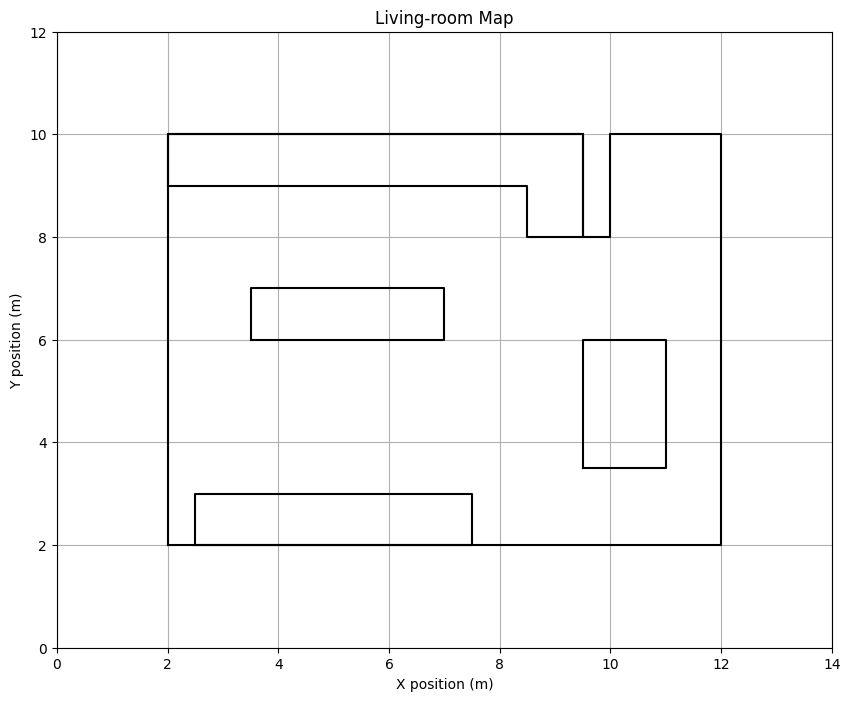

In [4]:
def plot_virtual_map(virtual_map, dimensions_only = False):
    """
    Plots the robot pose, virtual map, beam endpoints, and optionally grid cells to be updated.
    
    Parameters:
    - virtual_map: environment representation using lines.
    """
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Plot the virtual map (environment boundaries or walls)
    if not dimensions_only:
        plt.plot(virtual_map[0, :], virtual_map[1, :], 'k-')    
    
    # Set grid and axis limits
    plt.grid()
    plt.xlim([np.nanmin(virtual_map[0])-2,np.nanmax(virtual_map[0])+2]) # nanmin ignores nan numbers
    plt.ylim([np.nanmin(virtual_map[1])-2,np.nanmax(virtual_map[1])+2])  
    
    # Title and axis labels
    plt.title('Living-room Map')
    plt.xlabel('X position (m)')
    plt.ylabel('Y position (m)')

    return fig, ax

plot_virtual_map(virtual_map);

### **<span style="color:green"><b><i>ASSIGNMENT 1: Taking an observation</i></b></span>** 

To use the scanner, we will call the `take_observation()` method, passing it the map as an argument.

Similarly to the landmark-based sensors we saw in the last notebook, our laser scanner will produce observations as range-bearing pairs $\mathbf{z}_k = [r_k, \alpha_k]^T$. In other words, the measurements are in *polar coordinates*. Remember that you can express a sensor measurement given in polar coordinates ($\mathbf{z}_p=[r,\alpha]^T$) as cartesian coordinates ($\mathbf{z}_c=[z_x,z_y]^T$) with the following expression:

$$
\mathbf{z}_c = \begin{bmatrix} z_x \\ z_y \end{bmatrix} 
    = \begin{bmatrix} r \cos\alpha \\ r \sin\alpha \end{bmatrix} 
$$

Remember also that all the observations are taken from the point of view of the sensor, and thus are expressed in its local system of reference. To express the measurements in world space (on the map), you can use our old trick: **pose composition**, $\mathbf{x} \oplus \mathbf{z}_c$, being $\mathbf{x}$ the sensor pose.

Let's put all this into practice. Implement a function which takes a sensor reading (a scan) $\mathbf{z} = [\mathbf{z}_1, \dots, \mathbf{z}_K]$, that is, a set of $K$ points in polar coordinates and relative to the sensor pose, and plots those points on the map as a *point cloud*.

In [5]:
def plot_observations(z, pose, fig, ax, draw_lines = True, point_color = 'r'):
    """Draw a sensor observation taken from a given pose on a figure.

    Keyword arguments:
    z -- Laser observation
    pose -- Pose from which the observation was taken
    fig, ax -- Figure to plot in
    """
    for i in range (z.shape[1]):
        distance = z[0, i]
        angle = z[1, i]

        # calculate the cartesian coordinates of the observed point in local space
        x_local = distance*np.cos(angle)
        y_local = distance*np.sin(angle)

        # compose with the robot pose to express the point in global space
        pose_obs_global = tcomp(pose, np.vstack([x_local, y_local, 0]))
        x = pose_obs_global[0]
        y = pose_obs_global[1]

        if draw_lines:
            ax.plot([x, pose[0]], [y, pose[1]], 'g--', linewidth=1)
        ax.plot(x, y, 'o', markersize=4, color=point_color)

Use the following code to test it out:

In [6]:
def run_laser_and_plot(laser, pose, fig, ax, draw_lines = True, color='r'):
    laser.set_pose(pose)

    # take the measurement
    measurement = laser.take_observation(virtual_map)

    # Plot!
    DrawRobot(fig, ax, pose, axis_percent=0.015, color=color, linewidth=1.5);
    plot_observations(measurement, pose, fig, ax, draw_lines, color)
    return fig, ax


def test_laser(FOV, resolution, max_distance, distance_noise, angle_noise):
    laser = create_laser_at_origin(FOV, resolution, max_distance, np.diag([distance_noise, angle_noise]))

    fig, ax = plot_virtual_map(virtual_map);
    run_laser_and_plot(laser, np.vstack([6, 4, np.pi/2]), fig, ax);

ipywidgets.interact(
    test_laser,
    FOV=ipywidgets.FloatSlider(3 * np.pi/2, min=0.2, max=2 * np.pi),
    resolution=ipywidgets.FloatSlider(0.2, min=0.02, max=0.5, step=0.01),
    max_distance=ipywidgets.FloatSlider(10, min=1, max=10),
    distance_noise=ipywidgets.FloatSlider(0.01, min=0.0, max=0.2, step=0.01),
    angle_noise=ipywidgets.FloatSlider(0.001, min=0, max=0.05, step=0.001, readout_format='.3f')
)

interactive(children=(FloatSlider(value=4.71238898038469, description='FOV', max=6.283185307179586, min=0.2), …

<function __main__.test_laser(FOV, resolution, max_distance, distance_noise, angle_noise)>

Expected output:

<figure style="text-align:center">
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/assignment_2_1.png" width="600px" alt="">
    <figcaption>Fig. 2. Expected output of assignment 1: the scan taken from the robot pose, as a point cloud on the map.</figcaption>
</figure>

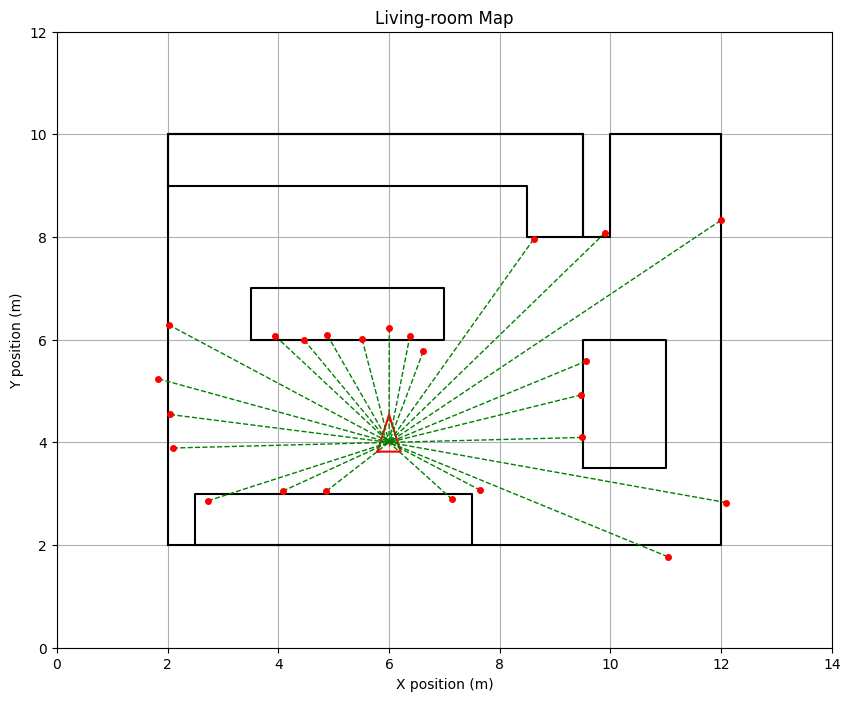

In [7]:
# Static run with the default slider values (the interactive widget above is not stored in the HTML/PDF)
np.random.seed(0)
test_laser(FOV=3*np.pi/2, resolution=0.2, max_distance=10, distance_noise=0.01, angle_noise=0.001)

### Comprobación con un caso de solución conocida

Para verificar `plot_observations()` sin depender del ruido, se crea un láser **sin ruido** con FOV $=\pi$ y resolución $\pi/2$, es decir, $\lfloor \pi / (\pi/2) \rfloor + 1 = 3$ haces a $-90°$, $0°$ y $+90°$ respecto al sensor. Se coloca en $\mathbf{x} = [6, 4, \pi/2]^T$ (mirando hacia $+y$):

- el haz de $-90°$ apunta hacia $+x$ (global $0°$) y choca con la mesa en $x = 9.5$: $r = 3.5$ m, punto $(9.5, 4)$;
- el de $0°$ apunta hacia $+y$ y choca con el sofá en $y = 6$: $r = 2$ m, punto $(6, 6)$;
- el de $+90°$ apunta hacia $-x$ y choca con la pared en $x = 2$: $r = 4$ m, punto $(2, 4)$.

Además se comprueba que la composición con `tcomp` coincide con la fórmula directa $x = x_s + r\cos(\alpha + \theta_s)$, $y = y_s + r\sin(\alpha + \theta_s)$, que es la que usa `Laser2D.draw_observation()`.

Number of beams: 3
Ranges (m):      [3.5 2.  4. ]
Angles (deg):    [-90.   0.  90.]
Global points:
 [[9.5 6.  2. ]
 [4.  6.  4. ]]
OK: tcomp(pose, [r cos a, r sin a, 0]) == [x + r cos(a + theta), y + r sin(a + theta)]


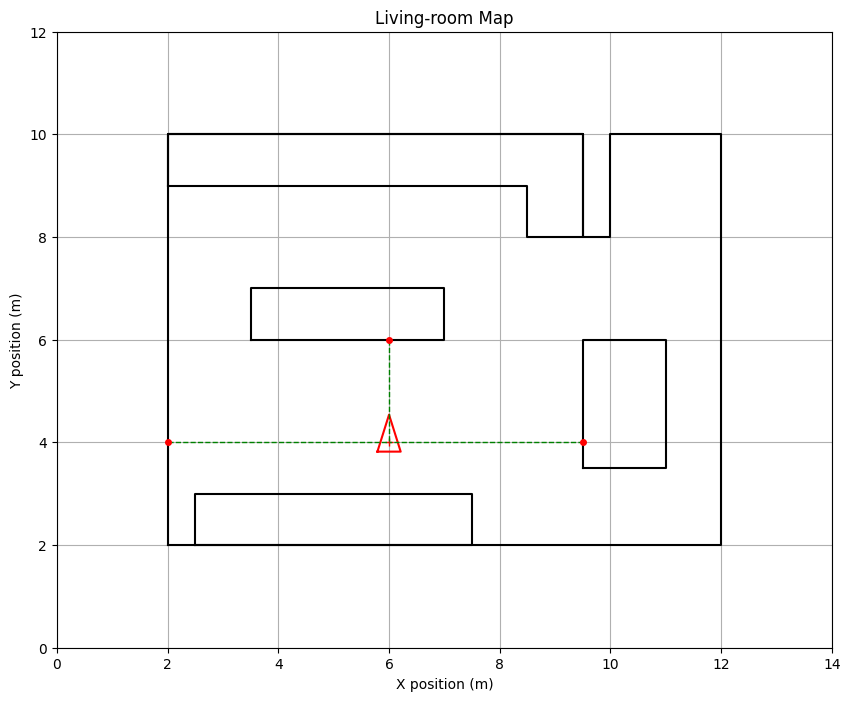

In [8]:
check_pose = np.vstack([6, 4, np.pi/2])
check_laser = Laser2D(np.pi, np.pi/2, 10, np.diag([0, 0]), check_pose)
z_check = check_laser.take_observation(virtual_map)
print('Number of beams:', z_check.shape[1])
print('Ranges (m):     ', z_check[0].round(3))
print('Angles (deg):   ', np.degrees(z_check[1]).round(1))

points = np.hstack([tcomp(check_pose, np.vstack([r*np.cos(a), r*np.sin(a), 0]))[:2] for r, a in z_check.T])
print('Global points:\n', points.round(3))
assert np.allclose(z_check[0], [3.5, 2, 4])
assert np.allclose(points, [[9.5, 6, 2], [4, 6, 4]])

# tcomp gives the same result as the direct formula (used by Laser2D.draw_observation) for any reading
rng = np.random.default_rng(0)
z_rand = np.vstack([rng.uniform(0, 10, 50), rng.uniform(-np.pi, np.pi, 50)])
pose_rand = np.vstack([1.0, -2.0, 2.5])
direct = np.vstack([pose_rand[0] + z_rand[0]*np.cos(z_rand[1] + pose_rand[2]),
                    pose_rand[1] + z_rand[0]*np.sin(z_rand[1] + pose_rand[2])])
composed = np.hstack([tcomp(pose_rand, np.vstack([r*np.cos(a), r*np.sin(a), 0]))[:2] for r, a in z_rand.T])
assert np.allclose(direct, composed)
print('OK: tcomp(pose, [r cos a, r sin a, 0]) == [x + r cos(a + theta), y + r sin(a + theta)]')

fig, ax = plot_virtual_map(virtual_map)
run_laser_and_plot(check_laser, check_pose, fig, ax);

### Experimento: incertidumbre de un punto medido

Las preguntas de *Thinking about it* piden comparar el efecto de $\sigma_r^2$ y $\sigma_\alpha^2$, y saber cómo calcular la incertidumbre de cada punto en cartesianas, con y sin incertidumbre en la pose. Se estudia un único punto medido a $r = 5$ m y $\alpha = 30°$ desde el sensor en $[6, 4, \pi/2]^T$, con la $Q$ por defecto del Assignment 1, $Q = \mathrm{diag}(\sigma_r^2, \sigma_\alpha^2) = \mathrm{diag}(0.01, 0.001)$:

1. **Polares → cartesianas locales.** $\mathbf{z}_c = f(\mathbf{z}_p) = [r\cos\alpha,\ r\sin\alpha]^T$ no es lineal, así que se linealiza con su jacobiano, igual que con los landmarks:
$$
J_{\mathbf{z}_p} = \frac{\partial \mathbf{z}_c}{\partial \mathbf{z}_p} = \begin{bmatrix} \cos\alpha & -r\sin\alpha \\ \sin\alpha & r\cos\alpha \end{bmatrix}, \qquad \Sigma_{\mathbf{z}_c} \approx J_{\mathbf{z}_p}\, Q\, J_{\mathbf{z}_p}^T
$$
2. **Local → global, con pose incierta.** $\mathbf{p} = \mathbf{x} \oplus \mathbf{z}_c$ depende de dos variables aleatorias independientes, así que se suman sus contribuciones:
$$
\Sigma_{\mathbf{p}} \approx J_{\mathbf{x}}\, \Sigma_{\mathbf{x}}\, J_{\mathbf{x}}^T + J_{\mathbf{z}}\, \Sigma_{\mathbf{z}_c}\, J_{\mathbf{z}}^T
$$
$$
J_{\mathbf{x}} = \frac{\partial (\mathbf{x} \oplus \mathbf{z}_c)}{\partial \mathbf{x}} = \begin{bmatrix} 1 & 0 & -z_x\sin\theta - z_y\cos\theta \\ 0 & 1 & z_x\cos\theta - z_y\sin\theta \end{bmatrix}
$$
$$
J_{\mathbf{z}} = \frac{\partial (\mathbf{x} \oplus \mathbf{z}_c)}{\partial \mathbf{z}_c} = \begin{bmatrix} \cos\theta & -\sin\theta \\ \sin\theta & \cos\theta \end{bmatrix}
$$
   con $\Sigma_{\mathbf{x}} = \mathrm{diag}(0.01, 0.01, 0.0025)$ ($\sigma_x = \sigma_y = 10$ cm, $\sigma_\theta \approx 2.9°$).

Cada aproximación se valida con 20 000 muestras de Monte Carlo. También se separan las dos fuentes del ruido del sensor (solo $\sigma_r$ y solo $\sigma_\alpha$) y se repite para varias distancias.

Point at r = 5.0 m, alpha = 30 deg, Q = diag(0.01, 0.001)
  noise source | std along the beam, across the beam (m)
    range only | 0.100, 0.000
    angle only | 0.000, 0.158
          both | 0.100, 0.158
Distance at which both contributions are equal: r* = sigma_r / sigma_alpha = 3.16 m

Sigma_zc with the Jacobian:
 [[ 0.0137 -0.0065]
 [-0.0065  0.0213]]
Sample covariance (Monte Carlo):
 [[ 0.0139 -0.0065]
 [-0.0065  0.0212]]

Global point (mean): [3.5  8.33]
Sigma_p, known pose:
 [[0.0213 0.0065]
 [0.0065 0.0137]]
Sigma_p, uncertain pose (Jacobians):
 [[0.0781 0.0336]
 [0.0336 0.0394]]
Sample covariance (Monte Carlo):
 [[0.0774 0.033 ]
 [0.033  0.0394]]
Principal std (m): known pose [0.158 0.1  ] | uncertain pose [0.312 0.141]

 r (m) | std along, across the beam (m) | pose uncertainty added: principal std (m)
     1 | [0.1   0.032] | [0.141 0.116]
     2 | [0.1   0.063] | [0.155 0.141]
     5 | [0.1   0.158] | [0.312 0.141]
    10 | [0.1   0.316] | [0.6   0.141]


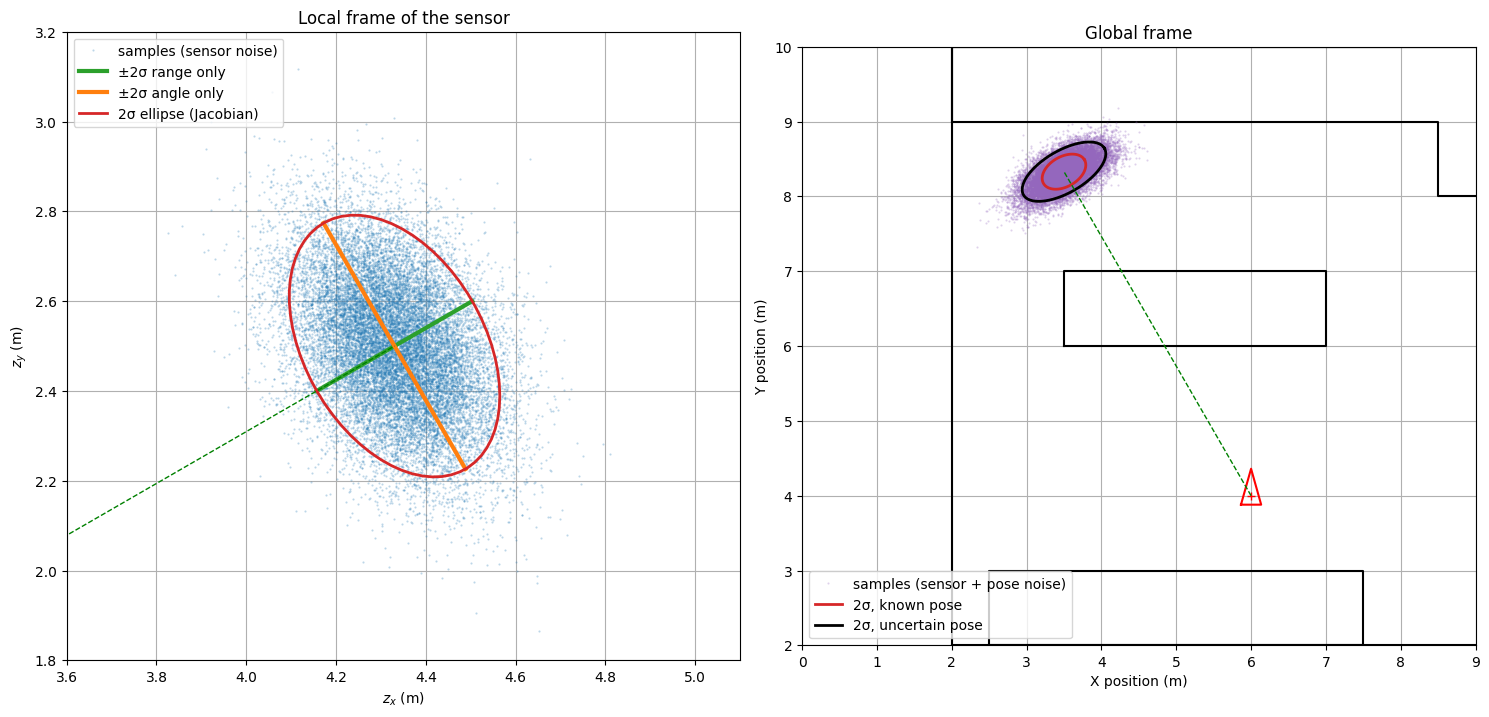

In [9]:
# Uncertainty of one laser point: polar -> local cartesian -> global (Jacobians vs. Monte Carlo)
from utils.PlotEllipse import PlotEllipse

def polar_to_cartesian_cov(r, alpha, Q):
    """Covariance of z_c = [r cos(alpha), r sin(alpha)] given the 2x2 covariance Q of z_p = [r, alpha]."""
    J = np.array([[np.cos(alpha), -r*np.sin(alpha)],
                  [np.sin(alpha),  r*np.cos(alpha)]])
    return J @ Q @ J.T

def point_global_cov(pose, z_c, P_pose, Sigma_c):
    """Covariance of the global point pose ⊕ z_c, given P_pose (3x3) and Sigma_c (2x2)."""
    c, s = np.cos(pose[2, 0]), np.sin(pose[2, 0])
    J_x = np.array([[1, 0, -z_c[0, 0]*s - z_c[1, 0]*c],
                    [0, 1,  z_c[0, 0]*c - z_c[1, 0]*s]])   # d(pose ⊕ z)/d pose  (2x3)
    J_z = np.array([[c, -s],
                    [s,  c]])                               # d(pose ⊕ z)/d z     (2x2)
    return J_x @ P_pose @ J_x.T + J_z @ Sigma_c @ J_z.T

def axes_std(cov):
    """Standard deviations along the principal axes (largest first)."""
    return np.sqrt(np.sort(np.linalg.eigvalsh(cov))[::-1].clip(min=0))

def beam_std(cov, alpha):
    """Standard deviations along and across a beam with local direction alpha."""
    u_along, u_across = np.array([np.cos(alpha), np.sin(alpha)]), np.array([-np.sin(alpha), np.cos(alpha)])
    return np.sqrt(np.clip([u_along @ cov @ u_along, u_across @ cov @ u_across], 0, None))

r0, a0 = 5.0, np.pi/6
Q = np.diag([0.01, 0.001])
sensor_pose = np.vstack([6, 4, np.pi/2])
P_pose = np.diag([0.01, 0.01, 0.0025])
n = 20000
rng = np.random.default_rng(0)

# 1) Sensor noise only, in the local frame of the sensor
print(f'Point at r = {r0} m, alpha = {np.degrees(a0):.0f} deg, Q = diag({Q[0, 0]}, {Q[1, 1]})')
print(f"{'noise source':>14} | std along the beam, across the beam (m)")
for name, Qi in [('range only', np.diag([Q[0, 0], 0])), ('angle only', np.diag([0, Q[1, 1]])), ('both', Q)]:
    s_along, s_across = beam_std(polar_to_cartesian_cov(r0, a0, Qi), a0)
    print(f'{name:>14} | {s_along:.3f}, {s_across:.3f}')
print(f'Distance at which both contributions are equal: r* = sigma_r / sigma_alpha = {np.sqrt(Q[0, 0]/Q[1, 1]):.2f} m')

zp = rng.multivariate_normal([r0, a0], Q, n).T
zc_samples = np.vstack([zp[0]*np.cos(zp[1]), zp[0]*np.sin(zp[1])])
Sigma_c = polar_to_cartesian_cov(r0, a0, Q)
print('\nSigma_zc with the Jacobian:\n', Sigma_c.round(4))
print('Sample covariance (Monte Carlo):\n', np.cov(zc_samples).round(4))

# 2) Global point with an uncertain sensor pose
z_c = np.vstack([r0*np.cos(a0), r0*np.sin(a0)])
poses = rng.multivariate_normal(sensor_pose.ravel(), P_pose, n).T
c, s = np.cos(poses[2]), np.sin(poses[2])
p_samples = poses[:2] + np.vstack([c*zc_samples[0] - s*zc_samples[1], s*zc_samples[0] + c*zc_samples[1]])
mean_p = tcomp(sensor_pose, np.vstack([z_c, 0]))[:2]
Sigma_p_sensor = point_global_cov(sensor_pose, z_c, np.zeros((3, 3)), Sigma_c)
Sigma_p = point_global_cov(sensor_pose, z_c, P_pose, Sigma_c)
print('\nGlobal point (mean):', mean_p.ravel().round(3))
print('Sigma_p, known pose:\n', Sigma_p_sensor.round(4))
print('Sigma_p, uncertain pose (Jacobians):\n', Sigma_p.round(4))
print('Sample covariance (Monte Carlo):\n', np.cov(p_samples).round(4))
print('Principal std (m): known pose', axes_std(Sigma_p_sensor).round(3),
      '| uncertain pose', axes_std(Sigma_p).round(3))

# 3) Effect of the distance
print(f"\n{'r (m)':>6} | std along, across the beam (m) | pose uncertainty added: principal std (m)")
for r in [1, 2, 5, 10]:
    zc_r = np.vstack([r*np.cos(a0), r*np.sin(a0)])
    Sc_r = polar_to_cartesian_cov(r, a0, Q)
    print(f'{r:>6} | {beam_std(Sc_r, a0).round(3)} | {axes_std(point_global_cov(sensor_pose, zc_r, P_pose, Sc_r)).round(3)}')

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
ax = axes[0]
ax.plot(zc_samples[0], zc_samples[1], '.', markersize=1, color='tab:blue', alpha=0.3, label='samples (sensor noise)')
u_beam = np.array([np.cos(a0), np.sin(a0)]); u_perp = np.array([-np.sin(a0), np.cos(a0)])
for vec, sig, col, lab in [(u_beam, np.sqrt(Q[0, 0]), 'tab:green', '±2σ range only'),
                           (u_perp, r0*np.sqrt(Q[1, 1]), 'tab:orange', '±2σ angle only')]:
    seg = z_c.ravel()[:, None] + np.outer(vec, [-2*sig, 2*sig])
    ax.plot(seg[0], seg[1], color=col, linewidth=3, label=lab)
PlotEllipse(fig, ax, z_c, Sigma_c, 2, color='tab:red', linewidth=2, label='2σ ellipse (Jacobian)')
ax.plot([0, z_c[0, 0]], [0, z_c[1, 0]], 'g--', linewidth=1)
ax.plot(0, 0, 'k^', markersize=10)
ax.set(title='Local frame of the sensor', xlabel='$z_x$ (m)', ylabel='$z_y$ (m)',
       xlim=(3.6, 5.1), ylim=(1.8, 3.2), aspect='equal')
ax.grid(True); ax.legend(loc='upper left')

ax = axes[1]
plt.sca(ax)
ax.plot(virtual_map[0], virtual_map[1], 'k-')
ax.plot(p_samples[0], p_samples[1], '.', markersize=1, color='tab:purple', alpha=0.3, label='samples (sensor + pose noise)')
PlotEllipse(fig, ax, mean_p, Sigma_p_sensor, 2, color='tab:red', linewidth=2, label='2σ, known pose')
PlotEllipse(fig, ax, mean_p, Sigma_p, 2, color='k', linewidth=2, label='2σ, uncertain pose')
ax.set(title='Global frame', xlabel='X position (m)', ylabel='Y position (m)', xlim=(0, 9), ylim=(2, 10), aspect='equal')
ax.grid(True)
DrawRobot(fig, ax, sensor_pose, axis_percent=0.015, color='r', linewidth=1.5)
ax.plot([sensor_pose[0, 0], mean_p[0, 0]], [sensor_pose[1, 0], mean_p[1, 0]], 'g--', linewidth=1)
ax.legend(loc='lower left')
plt.tight_layout()

**Observaciones:**

- **La elipse se orienta con el haz.** En el marco del sensor no está alineada con los ejes: tiene un semieje **a lo largo del haz** de $\sigma_r = 0.10$ m y otro **perpendicular** de $r\,\sigma_\alpha = 5 \cdot 0.032 = 0.158$ m. Por eso $\Sigma_{\mathbf{z}_c}$ tiene término cruzado ($-0.0065$) aunque $Q$ sea diagonal.
- **El ruido angular se amplifica con la distancia; el de rango no.** El error perpendicular crece linealmente con $r$ (0.032, 0.063, 0.158 y 0.316 m a 1, 2, 5 y 10 m), mientras que el radial se queda en 0.1 m. Las dos contribuciones son iguales en $r^* = \sigma_r/\sigma_\alpha = 3.16$ m: por debajo domina el rango y por encima, el ángulo.
- **La linealización es muy buena.** La covarianza calculada con el jacobiano coincide con la de 20 000 muestras de Monte Carlo (0.0137 / −0.0065 / 0.0213 frente a 0.0139 / −0.0065 / 0.0212 m²), porque $\sigma_\alpha$ es pequeño.
- **La incertidumbre de la pose se suma y también crece con la distancia.** Con $\Sigma_{\mathbf{x}} = \mathrm{diag}(0.01, 0.01, 0.0025)$, las desviaciones principales del punto pasan de (0.158, 0.100) a (0.312, 0.141) m, de nuevo confirmado por Monte Carlo. El error de orientación del robot actúa como un error angular más: perpendicular al haz, $\sigma_\perp^2 \approx \sigma_{xy}^2 + r^2(\sigma_\alpha^2 + \sigma_\theta^2)$, que a 10 m da $\sqrt{0.01 + 100 \cdot 0.0035} = 0.6$ m; y a lo largo del haz, $\sigma_\parallel^2 \approx \sigma_{xy}^2 + \sigma_r^2 = 0.02$, es decir, 0.141 m a cualquier distancia.

### <font color="blue"><b><i>Thinking about it</i></b></font>

Having completed the code above, you will be able to **answer the following questions**:

- Which has a greater impact on the reliability of the measurements: the variance of the distance reading, or the variance of the angle at which the measurement happens? Which would you guess is larger in real sensors, and why?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>En general, la <b>varianza del ángulo</b>, porque su efecto sobre la posición del punto <b>crece con la distancia</b>: un error angular σ<sub>α</sub> desplaza el punto perpendicularmente al haz unos r·σ<sub>α</sub>, mientras que el error de rango lo desplaza σ<sub>r</sub> a lo largo del haz, sea cual sea la distancia. Con los valores por defecto (σ<sub>r</sub> = 0.1 m, σ<sub>α</sub> = 0.032 rad), las dos contribuciones son iguales a r* = σ<sub>r</sub>/σ<sub>α</sub> ≈ 3.2 m; a 5 m el error angular ya produce 0.16 m y a 10 m, 0.32 m. En el Assignment 2 (σ<sub>α</sub> = 0.1 rad) es todavía más claro: unos 0.5 m a 5 m frente a 0.17 m de rango. En los sensores reales, en cambio, la incertidumbre <b>mayor es la del rango</b>. El ángulo de cada haz lo fija el mecanismo de giro, cuya posición se mide con un encoder muy preciso, así que su error es despreciable y muchos fabricantes solo dan la precisión en distancia (del orden de centímetros). El rango, en cambio, depende de medir el tiempo de vuelo, r = cΔt/2 (1 cm equivale a unos 67 ps), y le afectan la reflectividad y el ángulo de incidencia de la superficie, los bordes de los objetos, etc. Por eso a menudo se modela solo σ<sub>r</sub><sup>2</sup>, como dice el enunciado.</i></p>

- Without actually implementing it: how could we calculate the uncertainty about the position of each of the measured points (in cartesian coordinates)? *Hint: we already did this for the landmarks!*

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Igual que con los landmarks: la conversión <b>z</b><sub>c</sub> = [r cos α, r sin α]<sup>T</sup> no es lineal, así que se linealiza con su jacobiano y se propaga la covarianza, Σ<sub>zc</sub> ≈ J Q J<sup>T</sup>, con J = ∂<b>z</b><sub>c</sub>/∂<b>z</b><sub>p</sub> = [[cos α, −r sin α], [sin α, r cos α]]. Para expresarla en el mapa con la pose conocida, se gira con la rotación de la pose: Σ = R(θ) Σ<sub>zc</sub> R(θ)<sup>T</sup>. Se ha comprobado en el experimento anterior: para r = 5 m y α = 30°, el jacobiano da [[0.0137, −0.0065], [−0.0065, 0.0213]] m² y Monte Carlo con 20 000 muestras, [[0.0139, −0.0065], [−0.0065, 0.0212]] m². La elipse resultante tiene un eje σ<sub>r</sub> a lo largo del haz y otro r·σ<sub>α</sub> perpendicular a él. Se haría para cada punto del scan por separado, porque cada uno tiene su propio r y α.</i></p>

- We are assuming we know the pose of the robot, but what if there was also uncertainty associated with it? How do you combine both sources of uncertainty? *Hint: we **also** did this for the landmarks!*

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>El punto global es <b>p</b> = <b>x</b> ⊕ <b>z</b><sub>c</sub>, una función de dos variables aleatorias independientes (la pose y la medida). Se linealiza respecto a cada una y se <b>suman</b> las dos contribuciones, como al componer poses o al pasar los landmarks a coordenadas globales: Σ<sub>p</sub> ≈ J<sub>x</sub> Σ<sub>x</sub> J<sub>x</sub><sup>T</sup> + J<sub>z</sub> Σ<sub>zc</sub> J<sub>z</sub><sup>T</sup>, donde J<sub>x</sub> = ∂(<b>x</b> ⊕ <b>z</b>)/∂<b>x</b> es 2×3 (su tercera columna, [−z<sub>x</sub> sin θ − z<sub>y</sub> cos θ, z<sub>x</sub> cos θ − z<sub>y</sub> sin θ]<sup>T</sup>, convierte el error de orientación en un error de posición proporcional a la distancia, el «efecto palanca») y J<sub>z</sub> = R(θ). En el experimento, con Σ<sub>x</sub> = diag(0.01, 0.01, 0.0025), las desviaciones del punto a 5 m pasan de (0.158, 0.100) m a (0.312, 0.141) m, y a 10 m el eje mayor llega a 0.6 m; Monte Carlo lo confirma. Una consecuencia importante: el error de la pose es <b>el mismo para todos los puntos del scan</b>, así que esos puntos quedan correlados y el scan completo se desplaza o gira en bloque. Por eso, para construir un mapa con poses inciertas, hay que estimar la pose y el mapa a la vez (SLAM).</i></p>

### **<span style="color:green"><b><i>ASSIGNMENT 2: Exploring the environment</i></b></span>** 

Now that we can plot the measurements in global coordinates, we should be able to roughly reconstruct the contours of the map by moving around the environment and repeatedly taking observations from multiple poses. Let's try that out: 

orangered: pose = [4. 4. 0.]
    olive: pose = [6. 4. 0.]
     teal: pose = [8. 4. 0.]


  magenta: pose = [8.    6.    1.571]
   indigo: pose = [8.    8.    1.571]


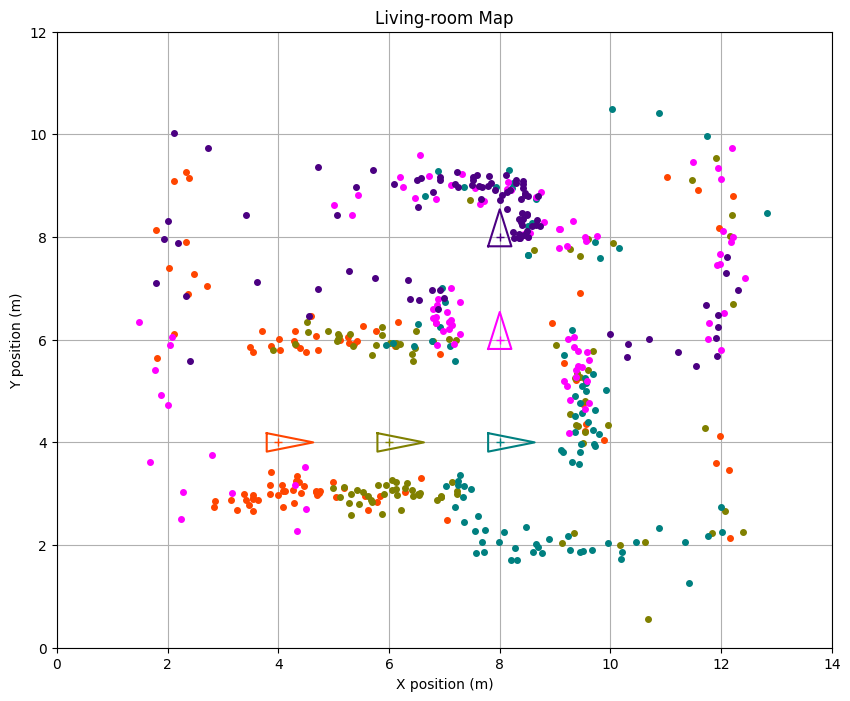

In [10]:
def explore_environment():
    laser = create_laser_at_origin(FOV = 3 * np.pi/2,
        resolution = 0.05,
        max_distance = 10,
        noise_cov = np.diag([0.03, 0.01]))

    # The robot must make these movements, in this order
    # 0, 0, 0
    # 2, 0, 0
    # 2, 0, 0
    # 0, 2, np.pi/2
    # 2, 0, 0
    # Format them correctly in the following list

    # each pose and its corresponding observations will have a different color
    pose_increments_list = [
        (np.vstack([0, 0, 0]), 'orangered'),
        (np.vstack([2, 0, 0]), 'olive'),
        (np.vstack([2, 0, 0]), 'teal'),
        (np.vstack([0, 2, np.pi/2]), 'magenta'),
        (np.vstack([2, 0, 0]), 'indigo'),
    ]

    fig, ax = plot_virtual_map(virtual_map, True); #create the base figure with the map dimensions, but without the lines

    current_pose = np.vstack([4,4,0]) # starting pose

    # take a step and read the sensor at the new pose
    for step, color in pose_increments_list:
        current_pose = tcomp(current_pose, step)
        print(f'{color:>9}: pose = {current_pose.ravel().round(3)}')
        run_laser_and_plot(laser, current_pose, fig, ax, False, color)

np.random.seed(0)
explore_environment()

Expected output:

<figure style="text-align:center">
    <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/robot_sensing/images/assignment_2_2.png" width="600px" alt="">
    <figcaption>Fig. 3. Expected output of assignment 2: the scans taken from the five poses, each one in a different color.</figcaption>
</figure>

**Observaciones del Assignment 2:**

- **Los incrementos son locales y se componen.** Las poses visitadas son $[4,4,0]$, $[6,4,0]$, $[8,4,0]$, $[8,6,\pi/2]$ y $[8,8,\pi/2]$. El cuarto incremento $[0, 2, \pi/2]$ mueve el robot 2 m hacia **su** izquierda (que con $\theta=0$ es $+y$ global) y lo gira 90°; el quinto, $[2,0,0]$, avanza 2 m en la nueva orientación, es decir, hacia $+y$. Si se sumaran los incrementos en lugar de componerlos, la última pose sería $[10, 6, \pi/2]$, que es incorrecta.
- **El primer incremento es nulo a propósito:** sirve para tomar la primera lectura en la pose inicial.
- **El ruido angular domina.** Con $Q = \mathrm{diag}(0.03, 0.01)$, $\sigma_r = 0.17$ m pero $\sigma_\alpha = 0.1$ rad (5.7°), así que a 5 m el error perpendicular es de unos 0.5 m. Por eso las paredes aparecen como bandas anchas y los puntos lejanos están más dispersos que los cercanos.
- **Con varias poses se ve el mapa.** Cada lectura cubre lo que la anterior no veía (por ejemplo, la cara superior de la mesa o la cocina) y la nube conjunta permite intuir el contorno de la habitación. Aun así, el ruido impide saber dónde está exactamente cada pared: ese es el problema de *mapping* que menciona la celda siguiente.

This looks pretty promising! Looking at this image, it is quite easy to get an intuition for the shape of the environment and the presence of obstacles. However, due to the noise in the sensor observations, it is difficult to tell where *exactly* the contours of the map really are. 

This is the problem of **mapping**, which we will talk about in more detail in chapter 6. It probably won't surprise you to learn that, in order to deal with these noisy observations, we will tackle this problem probabilistically. 

An even more complicated version of this process is necessary when the pose of the robot is uncertain, as we can't even reliably place the noisy points on the global map. To solve this (more realistic) case, we would need to simultaneously figure out the correct pose of the robot *and* build the map. This is the wonderfully named problem of **SLAM:** *Simultaneous Localization And Mapping*, which we will talk about in chapter 7. 

## <font color="orange"><b><i>AI Appendix</i></b></font>

### A.1 How I used AI
- **Model/tool:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Un asistente de programación basado en IA generativa (Claude Code con Claude Opus 5.5).</i></p>
- **What I asked AI to help with (bullets):**
  <div style="margin: 4px 0px 6px 5px; color:#2DD4BF; font-style: italic"><ul><li>Ayuda para completar <code>plot_observations()</code> y la lista de incrementos de <code>explore_environment()</code>.</li><li>Comprobación con un caso sin ruido de solución conocida y experimento de propagación de la incertidumbre de un punto (jacobianos frente a Monte Carlo).</li><li>Explicaciones para las respuestas de <i>Thinking about it</i>.</li><li>Detectar y corregir que <code>utils/laser/laser2D.py</code> fallaba con NumPy 2.4 al convertir arrays de un elemento en escalares (dos líneas con <code>.item()</code>).</li></ul></div>
- **Best prompt I used (paste):**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"></p>
- **What I kept vs. changed from the AI output:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>He revisado el código contra las fórmulas del enunciado (polares → cartesianas y composición con la pose), he comprobado con un láser sin ruido que los alcances y los puntos globales coinciden con los calculados a mano, y que la composición con <code>tcomp</code> da lo mismo que la fórmula directa de <code>Laser2D.draw_observation()</code>. También he validado con Monte Carlo las covarianzas usadas en las respuestas antes de quedarme con la solución.</i></p>

### A.2 AI review 
Ask one generative AI to review your memo using this prompt:

```
Act as a technical reviewer of this robotics notebook. Read my memo and return exactly 5 bullet points:

- two on theory (key ideas),
- two on practice (relevant programming concepts of python used, not particular functions or variables),
- one on how to improve the code (most critical aspect: limitations, parameter choices, runtime/robustness, possible bugs).

Keep each bullet ≤15 words and make them specific to my work.
```

Paste its **5** items here:

*AI used for the review: the same AI coding assistant (Claude Code with Claude Opus 5.5).*

- **(Theory 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>El ruido angular se amplifica con la distancia (r·σ<sub>α</sub>); el de rango, no.</i></p>
- **(Theory 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>La incertidumbre de cada punto se propaga con jacobianos: polar→cartesiano y composición.</i></p>
- **(Practice 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Asserts sobre casos sin ruido de solución conocida verifican la implementación objetivamente.</i></p>
- **(Practice 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Semillas fijas y Monte Carlo vectorizado con NumPy hacen los resultados reproducibles.</i></p>
- **(Improvement)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i><code>plot_observations</code> dibuja punto a punto; vectorizar y filtrar lecturas a <code>max_distance</code>.</i></p>

Finally, **do you agree with them?**, **would you have selected others?** 
    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Estoy de acuerdo con los cinco puntos. Los teóricos resumen las dos ideas que se usan después en mapping y SLAM: cada punto del scan tiene una elipse que depende de su distancia, y la incertidumbre de la pose se suma a la del sensor. La mejora también es real: <code>plot_observations()</code> llama a <code>tcomp</code> y a <code>ax.plot</code> una vez por haz, lo que con 95 haces y 5 poses ya es lento, y se podría hacer con una sola rotación matricial de todos los puntos. Además, si un haz no choca con nada, <code>Laser2D</code> devuelve <code>max_distance</code> (más ruido) y se dibujaría un punto falso; en esta habitación no ocurre porque todo está a menos de 10 m, pero con un mapa abierto habría que descartar esas lecturas. Habría añadido otro punto de mejora: <code>take_observation()</code> recorre en Python todos los haces y todos los segmentos del mapa, y su comprobación de dirección compara solo el signo de los ángulos, lo que es frágil para haces cercanos a 0 o ±π.</i></p>